## Practice Activity 7-1: Association Rules Mining

In the reading you analyzed transactions from a bakery. In this activity you will carry out a very similar analysis for purchases from a grocery store.

**Name: Nicolas Ramel**


In [1]:
import pandas as pd
from plotnine import *

from mlxtend.frequent_patterns import apriori, association_rules as make_rules

## Groceries data set

- One month (30 days) of real point-of-sale transactions from a grocery store.
- 9,835 transactions (baskets).
- 169 product categories, such as whole milk, yogurt, bottled beer, etc.
- Source: the data set `Groceries` in the R package `arules`, provided by Hahsler, Hornik, and Reutterer. The copy we use is a plain-text version hosted on GitHub.


The file format is different from the bakery file. The bakery file had one row per item bought. This file has **one line per transaction**, and each line is a comma-separated list of the items in that basket. Different baskets have different numbers of items.

The next cell reads each line into a single text column. (Normal CSV reading expects every row to have the same number of columns, so we read each line as one string, using a separator `"|"` that never occurs in the file.)

In [2]:
import csv

raw = pd.read_csv(
    "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/groceries.csv",
    header = None,
    names=["basket"],
    sep = "|",
    quoting=csv.QUOTE_NONE
)

In [3]:
raw

,basket
0,"citrus fruit,semi-finished bread,margarine,rea..."
1,"tropical fruit,yogurt,coffee"
2,whole milk
3,"pip fruit,yogurt,cream cheese ,meat spreads"
4,"other vegetables,whole milk,condensed milk,lon..."
...,...
9830,"sausage,chicken,beef,hamburger meat,citrus fru..."
9831,cooking chocolate
9832,"chicken,citrus fruit,other vegetables,butter,y..."
9833,"semi-finished bread,bottled water,soda,bottled..."


We'll start with the data in long format like in the reading.

- Make a column `basket_id` from the row number (`raw.index`).
- Split the text in `raw["basket"]` at the commas, using `.str.split(",")`. This produces a *list* of items in each row.
- Use `.explode(...)` on the column of lists to get one row per item.
- Keep only `basket_id` and `item`, and use `.reset_index(drop=True)`.
- Trim spaces

In [4]:
long=(raw
      .assign(basket_id=raw.index, item = raw["basket"].str.split(","))
      .explode("item")
      [["basket_id", "item"]]
      .reset_index(drop=True))

long["item"] =long["item"].str.strip()
long

,basket_id,item
0,0,citrus fruit
1,0,semi-finished bread
2,0,margarine
3,0,ready soups
4,1,tropical fruit
...,...,...
43362,9834,chicken
43363,9834,tropical fruit
43364,9834,other vegetables
43365,9834,vinegar


1. Build the transaction-by-item table `basket`. There should be one row per basket, one column per item, with `True` if the item is in the basket and `False` otherwise.

In [5]:
basket = pd.crosstab(long["basket_id"],long["item"]).gt(0)
basket

item,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
basket_id,,,,,,,,,,,,,,,,,,,,,
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9830,False,False,False,False,False,False,False,False,False,True,...,False,False,False,True,False,False,False,True,False,False
9831,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9832,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False


2.  Compute the size (number of items) of each basket and store it in `basket_sizes`.

In [6]:
basket_sizes=basket.sum(axis = 1).rename("n_items")

basket_sizes

basket_id
0        4
1        3
2        1
3        4
4        4
        ..
9830    17
9831     1
9832    10
9833     4
9834     5
Name: n_items, Length: 9835, dtype: int64

3. Summarize the distribution of the number of items.

In [7]:
basket_sizes.describe()

count    9835.000000
mean        4.409456
std         3.589385
min         1.000000
25%         2.000000
50%         3.000000
75%         6.000000
max        32.000000
Name: n_items, dtype: float64

4. Compute the support of every item, sorted from largest to smallest, and store it in `item_support`. Then make a horizontal bar chart of the 15 most popular items.

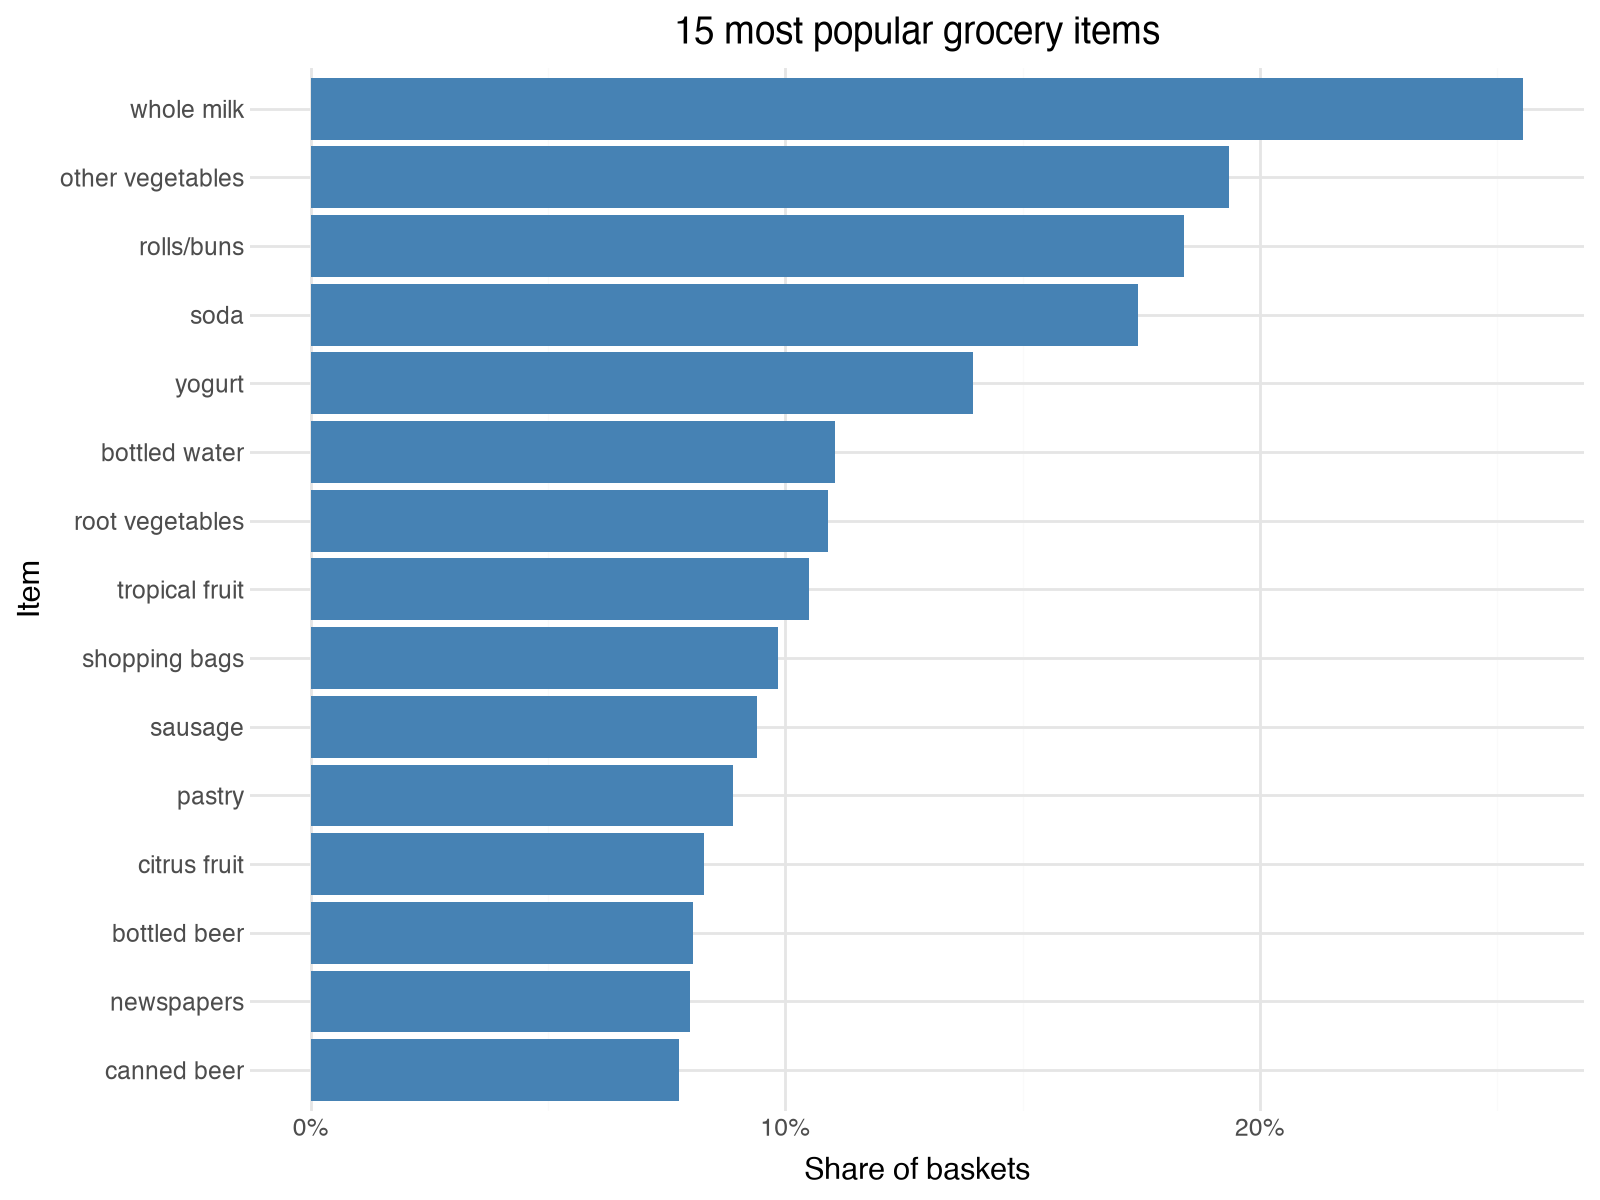

In [8]:
item_support =basket.mean(axis=0).sort_values(ascending = False)

top_items=item_support.head(15).rename("support").reset_index()

(ggplot(top_items, aes(x="reorder(item, support)",y="support"))
 + geom_col(fill = "steelblue")
 + coord_flip()
 + scale_y_continuous(labels=lambda values: [f"{v:.0%}" for v in values])
 + labs(x="Item", y = "Share of baskets", title="15 most popular grocery items")
 + theme_minimal()
 + theme(figure_size=(8, 6)))

5. Consider the basket sizes and the item supports. Which item is most popular, and in what percentage of baskets does it appear? Which items are most common? What does this suggest about the "popular items co-occur just by chance" problem discussed in the reading?

Whole milk is the most popular item, appearing in 25.55% of baskets. Other vegetables (19.35%), rolls/buns (18.39%), soda (17.44%), and yogurt (13.95%) are also common. The median basket contains 3 items, while the mean is 4.41 and the maximum is 32. With several items in many baskets and high supports for these products, popular items can occur together frequently just by chance. Confidence should be compared with the consequent's overall support using lift.

6. Consider the rule **{yogurt} → {whole milk}**. Compute and interpret the confidence of this rule.


In [9]:
yogurt_milk_support =basket[["yogurt", "whole milk"]].all(axis = 1).mean()
yogurt_support=basket["yogurt"].mean()

confidence_yogurt_milk = yogurt_milk_support/yogurt_support
confidence_yogurt_milk

np.float64(0.40160349854227406)

The confidence is 0.401603, or 40.16%. Of the 1,372 baskets containing yogurt, 551 also contain whole milk.

7. Compute and interpret the **lift** of {yogurt} → {whole milk}.

In [10]:
milk_support = basket["whole milk"].mean()
lift_yogurt_milk=confidence_yogurt_milk / milk_support

lift_yogurt_milk

np.float64(1.5717351405345266)

The lift is 1.571735. Whole milk appears in 25.55% of all baskets, compared with 40.16% of yogurt baskets. It is about 1.57 times as common, or 57.17% more likely, in baskets containing yogurt than in baskets overall.

8. Now compute and interpret the confidence and lift for the rule {whole milk} → {yogurt}.

In [11]:
confidence_milk_yogurt=yogurt_milk_support / milk_support
lift_milk_yogurt = confidence_milk_yogurt/yogurt_support

pd.Series({"confidence":confidence_milk_yogurt, "lift": lift_milk_yogurt})

confidence    0.219260
lift          1.571735
dtype: float64

The confidence is 0.219260, or 21.93%: 551 of the 2,513 baskets containing whole milk also contain yogurt. The lift is still 1.571735, so yogurt is about 1.57 times as common in whole-milk baskets as in all baskets, where its support is 13.95%. Reversing the rule changes confidence because the antecedent changes; lift is the same in both directions.

9. Write two functions.

- `support(items, onehot)`: returns the share of baskets that contain **all** of the items in the list `items`.
- `rule_metrics(antecedent, consequent, onehot)`: returns a Pandas Series with the `support`, `confidence`, and `lift` of the rule `antecedent -> consequent`. Both `antecedent` and `consequent` are *lists* of items.

Test the functions on `["yogurt"]` → `["whole milk"]`. The values should match the ones you computed earlier.

In [12]:
def support(items,onehot):
    return onehot[items].all(axis=1).mean()


def rule_metrics(antecedent, consequent,onehot):
    joint_support =support(antecedent + consequent, onehot)
    confidence=joint_support / support(antecedent,onehot)
    lift = confidence/support(consequent, onehot)
    return pd.Series({"support": joint_support,
                      "confidence":confidence, "lift": lift})

rule_metrics(["yogurt"],["whole milk"], basket)

support       0.056024
confidence    0.401603
lift          1.571735
dtype: float64

10. Whole milk is in about a quarter of all baskets. Consider the rules `{X} → {whole milk}` for the five antecedents `X` in the next cell. Before running anything, predict: for which of these will the lift be **above 1**? For which might the confidence look decent but the lift be **close to or below 1**? Just think about this before proceeding.

Prediction: yogurt and other vegetables should have lift above 1 because they seem likely to be bought with milk. Rolls/buns and bottled water might have reasonable confidence but lift closer to 1. Soda might have lift close to or below 1 because milk is already common and soda is another beverage.

In [13]:
antecedents = pd.Series(["yogurt", "rolls/buns", "bottled water", "soda", "other vegetables"])

11. Compute the support, confidence, and lift of `{X} → {whole milk}` for each of the five antecedents above, and display the results sorted by lift (largest first). Compare to your predictions. Hint: Use `apply` with `lambda` on the Series of antecedents.


In [14]:
milk_rules =antecedents.apply(lambda item: rule_metrics([item], ["whole milk"],basket))
milk_rules.index=antecedents
milk_rules.index.name = "antecedent"

milk_rules.sort_values("lift",ascending=False)

,support,confidence,lift
antecedent,,,
yogurt,0.056024,0.401603,1.571735
other vegetables,0.074835,0.386758,1.513634
bottled water,0.034367,0.310948,1.216940
rolls/buns,0.056634,0.307905,1.205032
soda,0.040061,0.229738,0.899112


Yogurt has the highest lift (1.57), followed by other vegetables (1.51), bottled water (1.22), rolls/buns (1.21), and soda (0.90). As predicted, yogurt and other vegetables have lift above 1, while soda is below 1. Bottled water and rolls/buns also have lift above 1, but their roughly 31% confidence represents only a modest increase over the 25.55% baseline for whole milk. Soda has 22.97% confidence, below that baseline.

12. Run `apriori` on `basket` with `min_support=0.01` and store the result in `frequent_itemsets`. Then add a column `n_items` giving the number of items in each itemset.

In [15]:
frequent_itemsets=apriori(basket, min_support = 0.01, use_colnames=True)
frequent_itemsets["n_items"] = frequent_itemsets["itemsets"].apply(len)

frequent_itemsets

,support,itemsets,n_items
0,0.033452,frozenset({UHT-milk}),1
1,0.017692,frozenset({baking powder}),1
2,0.052466,frozenset({beef}),1
3,0.033249,frozenset({berries}),1
4,0.026029,frozenset({beverages}),1
...,...,...,...
328,0.011998,"frozenset({whole milk, root vegetables, tropic...",3
329,0.014540,"frozenset({whole milk, yogurt, root vegetables})",3
330,0.010473,"frozenset({whole milk, yogurt, soda})",3
331,0.015150,"frozenset({whole milk, yogurt, tropical fruit})",3


13. Generate the rules with `make_rules`, keeping rules with confidence of at least 0.20. Store them in `rules` and print how many there are.

In [16]:
rules =make_rules(frequent_itemsets, metric="confidence",min_threshold = 0.20)
print("Number of rules:",len(rules))

Number of rules: 234


14. Make the rules easier to read. Create a copy `rules_display` of `rules` and add three columns:

- `antecedent`: the antecedent items as text, e.g. `"tropical fruit, yogurt"`
- `consequent`: the consequent items as text
- `transactions`: the number of baskets that contain the whole rule (support times the number of baskets, rounded to an integer)

Then display the columns `antecedent`, `consequent`, `support`, `confidence`, `lift`, `transactions` for the first 8 rules.

In [17]:
rules_display=rules.copy()
rules_display["antecedent"] = rules_display["antecedents"].apply(lambda items: ", ".join(sorted(items)))
rules_display["consequent"]=rules_display["consequents"].apply(lambda items: ", ".join(sorted(items)))
rules_display["transactions"] = (rules_display["support"]*len(basket)).round().astype(int)

rule_columns=["antecedent", "consequent", "support", "confidence", "lift", "transactions"]
rules_display[rule_columns].head(8)

,antecedent,consequent,support,confidence,lift,transactions
0,beef,other vegetables,0.019725,0.375969,1.943066,194
1,beef,rolls/buns,0.013625,0.259690,1.411858,134
2,beef,root vegetables,0.017387,0.331395,3.040367,171
3,beef,whole milk,0.021251,0.405039,1.585180,209
4,beef,yogurt,0.011693,0.222868,1.597601,115
5,berries,other vegetables,0.010269,0.308869,1.596280,101
6,berries,whole milk,0.011795,0.354740,1.388328,116
7,berries,yogurt,0.010574,0.318043,2.279848,104


15. Show the 10 rules with the highest **confidence**. What do the highest-confidence rules have in common? Why is confidence alone a poor guide here?

In [18]:
highest_confidence =rules_display.sort_values(
    ["confidence", "antecedent", "consequent"], ascending=[False,True, True]
).head(10)

highest_confidence[rule_columns]

,antecedent,consequent,support,confidence,lift,transactions
157,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
186,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999,121
164,"curd, yogurt",whole milk,0.010066,0.582353,2.279125,99
154,"butter, other vegetables",whole milk,0.011490,0.573604,2.244885,113
223,"root vegetables, tropical fruit",whole milk,0.011998,0.570048,2.230969,118
226,"root vegetables, yogurt",whole milk,0.014540,0.562992,2.203354,143
166,"domestic eggs, other vegetables",whole milk,0.012303,0.552511,2.162336,121
233,"whipped/sour cream, yogurt",whole milk,0.010880,0.524510,2.052747,107
215,"rolls/buns, root vegetables",whole milk,0.012710,0.523013,2.046888,125
172,"other vegetables, pip fruit",whole milk,0.013523,0.517510,2.025351,133


All ten rules have two-item antecedents. Eight predict whole milk, and two predict other vegetables. These consequents are already common, appearing in 25.55% and 19.35% of baskets, respectively. A high confidence can partly reflect that popularity, so it does not show how much the rule improves on the baseline. Lift provides that comparison.

16. Show the 10 rules with the highest **lift**. Compare this list with the highest-confidence list. What kinds of products appear now? Look at the `support` and `transactions` columns: how much evidence is each of these rules based on?

In [19]:
highest_lift=rules_display.sort_values(
    ["lift", "antecedent", "consequent"],ascending=[False, True,True]
).head(10)
highest_lift[rule_columns]

,antecedent,consequent,support,confidence,lift,transactions
156,"citrus fruit, other vegetables",root vegetables,0.010371,0.359155,3.295045,102
207,"other vegetables, yogurt",whipped/sour cream,0.010168,0.234192,3.267062,100
185,"other vegetables, tropical fruit",root vegetables,0.012303,0.342776,3.144780,121
2,beef,root vegetables,0.017387,0.331395,3.040367,171
157,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
186,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999,121
187,"other vegetables, whole milk",root vegetables,0.023183,0.309783,2.842082,228
190,root vegetables,"other vegetables, whole milk",0.023183,0.212687,2.842082,228
155,butter,"other vegetables, whole milk",0.011490,0.207339,2.770630,113
163,"curd, whole milk",yogurt,0.010066,0.385214,2.761356,99


The highest-lift rules feature combinations involving root vegetables, other vegetables, citrus and tropical fruit, beef, whipped/sour cream, curd, and yogurt. Compared with the highest-confidence list, the consequents are more varied and the rules emphasize stronger associations relative to each consequent's baseline. Their supports range from about 1.01% to 2.32%, corresponding to 99–228 baskets out of 9,835. These strong associations therefore rest on a relatively small share of transactions.

17. Create `interesting_rules`: the rules with **confidence of at least 0.30 and lift of at least 1.5**, sorted by lift (largest first).


In [20]:
interesting_rules = rules_display.loc[
    (rules_display["confidence"]>=0.30) & (rules_display["lift"] >= 1.5)
].sort_values(["lift", "antecedent", "consequent"], ascending=[False,True, True])

interesting_rules[rule_columns]

,antecedent,consequent,support,confidence,lift,transactions
156,"citrus fruit, other vegetables",root vegetables,0.010371,0.359155,3.295045,102
185,"other vegetables, tropical fruit",root vegetables,0.012303,0.342776,3.144780,121
2,beef,root vegetables,0.017387,0.331395,3.040367,171
157,"citrus fruit, root vegetables",other vegetables,0.010371,0.586207,3.029608,102
186,"root vegetables, tropical fruit",other vegetables,0.012303,0.584541,3.020999,121
...,...,...,...,...,...,...
89,onions,whole milk,0.012100,0.390164,1.526965,119
72,hygiene articles,whole milk,0.012811,0.388889,1.521975,126
17,brown bread,whole milk,0.025216,0.388715,1.521293,248
106,other vegetables,whole milk,0.074835,0.386758,1.513634,736


18. Choose **one** rule from the table and interpret its **support**, **confidence**, and **lift** with numbers, as you did for {yogurt} → {whole milk}.

For {citrus fruit, other vegetables} → {root vegetables}, support is 0.010371, meaning all three items appear together in 1.04% of baskets, or 102 of 9,835 transactions. Confidence is 0.359155: 35.92% of baskets containing both citrus fruit and other vegetables also contain root vegetables. Lift is 3.295045, so root vegetables occur about 3.30 times as often in those baskets as in baskets overall, where their support is 10.90%.

19. The manager wants to **increase sales of yogurt**. Which products should the store link to yogurt (shelf placement, a joint promotion, a recommendation)?

In [21]:
yogurt_rules=interesting_rules.loc[
    interesting_rules["consequents"] == frozenset(["yogurt"])
]
yogurt_single_items = yogurt_rules.loc[yogurt_rules["antecedents"].apply(len)==1]

yogurt_single_items[rule_columns]

,antecedent,consequent,support,confidence,lift,transactions
47,curd,yogurt,0.017285,0.324427,2.325615,170
7,berries,yogurt,0.010574,0.318043,2.279848,104
43,cream cheese,yogurt,0.012405,0.312821,2.242412,122


Link yogurt to curd, berries, and cream cheese through nearby shelf displays, joint promotions, or recommendations. Among curd baskets, 32.44% include yogurt (lift 2.33; 170 joint transactions). For berries the confidence is 31.80% (lift 2.28; 104 transactions), and for cream cheese it is 31.28% (lift 2.24; 122 transactions). These exceed yogurt's overall support of 13.95%. Targeted offers could also recommend yogurt to shoppers buying curd with whole milk (38.52% confidence; lift 2.76) or tropical fruit with whole milk (35.82%; lift 2.57). Test the promotions to determine whether these observed associations lead to increased yogurt sales.

---
## References and attribution


- Hahsler, M., Gr&uuml;n, B., and Hornik, K. (2005). arules: A computational environment for mining association rules and frequent item sets. *Journal of Statistical Software*, 14(15). (The R package that distributes the data.)
- Data copy: GitHub repository `stedy/Machine-Learning-with-R-datasets` (`groceries.csv`), the data used in Lantz, B., *Machine Learning with R*.
- Raschka, S. (2018). MLxtend: Providing machine learning and data science utilities and extensions to Python's scientific computing stack. *Journal of Open Source Software*, 3(24), 638. <https://doi.org/10.21105/joss.00638>


**Preparation of this notebook:** drafted with the assistance of generative AI tools (ChatGPT and Claude).